In [ ]:
import os
import shutil
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
!git clone https://github.com/spMohanty/PlantVillage-Dataset.git

Cloning into 'PlantVillage-Dataset'...
remote: Enumerating objects: 163264, done.
remote: Counting objects: 100% (35/35), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 163264 (delta 16), reused 25 (delta 9), pack-reused 163229 (from 1)
Receiving objects: 100% (163264/163264), 2.00 GiB | 21.63 MiB/s, done.
Resolving deltas: 100% (115/115), done.
Updating files: 100% (182404/182404), done.


In [ ]:
dataset_path = "/content/PlantVillage-Dataset/raw/color"
print(os.listdir(dataset_path)[:20])

['Corn_(maize)___Northern_Leaf_Blight', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Cherry_(including_sour)___healthy', 'Blueberry___healthy', 'Grape___Black_rot', 'Raspberry___healthy', 'Peach___healthy', 'Tomato___Early_blight', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Apple___Apple_scab', 'Tomato___healthy', 'Apple___Black_rot', 'Tomato___Septoria_leaf_spot', 'Corn_(maize)___healthy', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Target_Spot', 'Peach___Bacterial_spot', 'Potato___healthy']


In [ ]:
tomato_classes = [
    folder for folder in os.listdir(dataset_path)
    if folder.startswith("Tomato")
]

print("Number of Tomato Classes:", len(tomato_classes))
print(tomato_classes)

Number of Tomato Classes: 10
['Tomato___Early_blight', 'Tomato___healthy', 'Tomato___Septoria_leaf_spot', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Bacterial_spot', 'Tomato___Tomato_mosaic_virus']


In [ ]:
tomato_path = "/content/tomato_dataset"

os.makedirs(tomato_path, exist_ok=True)

for class_name in tomato_classes:
    os.makedirs(os.path.join(tomato_path, class_name), exist_ok=True)

In [ ]:
for class_name in tomato_classes:
    source_folder = os.path.join(dataset_path, class_name)
    destination_folder = os.path.join(tomato_path, class_name)

    files = os.listdir(source_folder)

    for file in files:
        source_file = os.path.join(source_folder, file)
        destination_file = os.path.join(destination_folder, file)
        shutil.copy(source_file, destination_file)

print("Tomato images copied successfully")

Tomato images copied successfully


In [ ]:
class_counts = {}

for class_name in tomato_classes:
    folder_path = os.path.join(tomato_path, class_name)
    class_counts[class_name] = len(os.listdir(folder_path))

print(class_counts)

{'Tomato___Early_blight': 1000, 'Tomato___healthy': 1591, 'Tomato___Septoria_leaf_spot': 1771, 'Tomato___Late_blight': 1909, 'Tomato___Leaf_Mold': 952, 'Tomato___Target_Spot': 1404, 'Tomato___Tomato_Yellow_Leaf_Curl_Virus': 5357, 'Tomato___Spider_mites Two-spotted_spider_mite': 1676, 'Tomato___Bacterial_spot': 2127, 'Tomato___Tomato_mosaic_virus': 373}


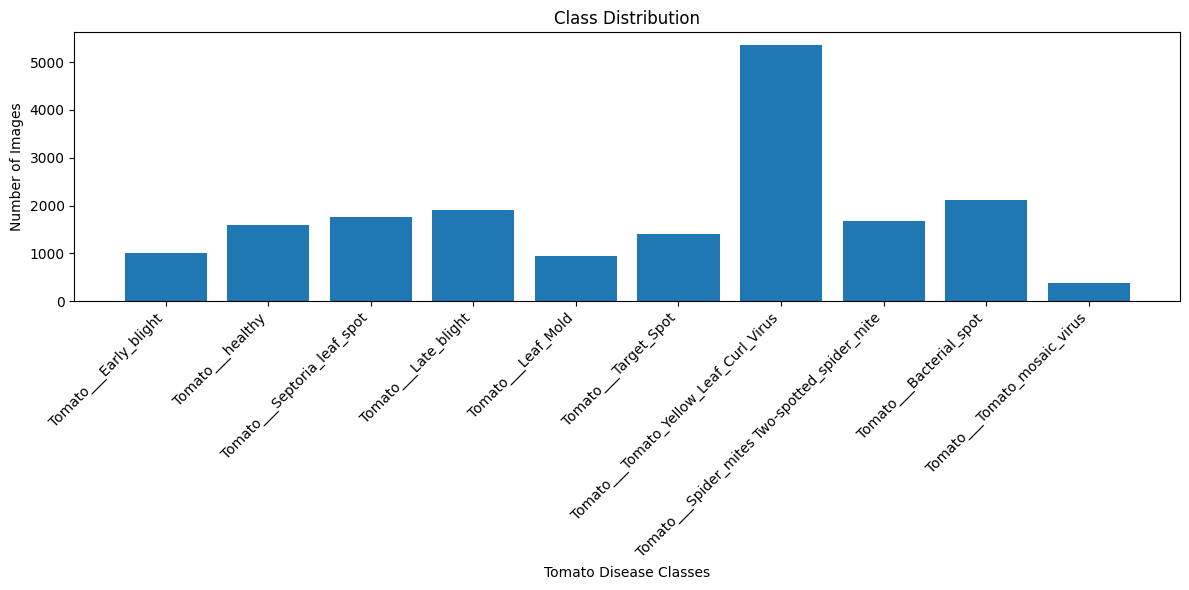

In [ ]:
plt.figure(figsize=(12, 6))
plt.bar(class_counts.keys(), class_counts.values())
plt.xticks(rotation=45, ha="right")
plt.xlabel("Tomato Disease Classes")
plt.ylabel("Number of Images")
plt.title("Class Distribution")
plt.tight_layout()
plt.show()

In [ ]:
img_size = (128, 128)
batch_size = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    tomato_path,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=img_size,
    batch_size=batch_size
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    tomato_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=img_size,
    batch_size=batch_size
)

Found 18160 files belonging to 10 classes.
Using 14528 files for training.
Found 18160 files belonging to 10 classes.
Using 3632 files for validation.


In [ ]:
class_names = train_ds.class_names

print("Class Names:")
print(class_names)
print("Number of Classes:", len(class_names))

Class Names:
['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']
Number of Classes: 10


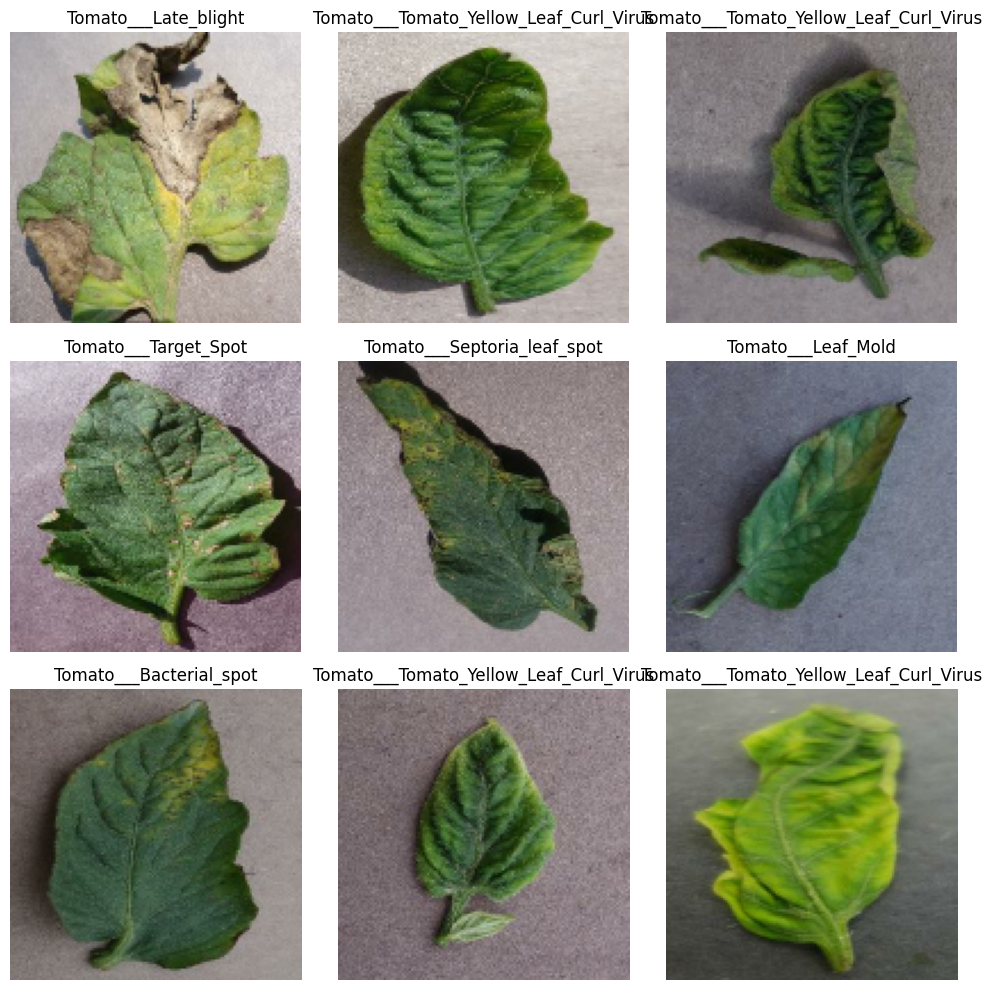

In [ ]:
plt.figure(figsize=(10, 10))

for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
normalization_layer = layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

val_ds = val_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.shuffle(1000).prefetch(
    buffer_size=AUTOTUNE
)

val_ds = val_ds.prefetch(
    buffer_size=AUTOTUNE
)

In [ ]:
train_ds = train_ds.cache().shuffle(1000).prefetch(
    buffer_size=AUTOTUNE
)

val_ds = val_ds.cache().prefetch(
    buffer_size=AUTOTUNE
)

In [ ]:
model = keras.Sequential([
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=(128, 128, 3)
    ),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.5),

    layers.Dense(
        len(class_names),
        activation="softmax"
    )
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,930 (12.61 MB)

 Trainable params: 3,305,930 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3
)

Epoch 1/3
454/454 ━━━━━━━━━━━━━━━━━━━━ 526s 1s/step - accuracy: 0.5891 - loss: 1.2160 - val_accuracy: 0.7971 - val_loss: 0.6363
Epoch 2/3
454/454 ━━━━━━━━━━━━━━━━━━━━ 526s 1s/step - accuracy: 0.7761 - loss: 0.6564 - val_accuracy: 0.8544 - val_loss: 0.4156
Epoch 3/3
454/454 ━━━━━━━━━━━━━━━━━━━━ 519s 1s/step - accuracy: 0.8287 - loss: 0.5032 - val_accuracy: 0.8824 - val_loss: 0.3364


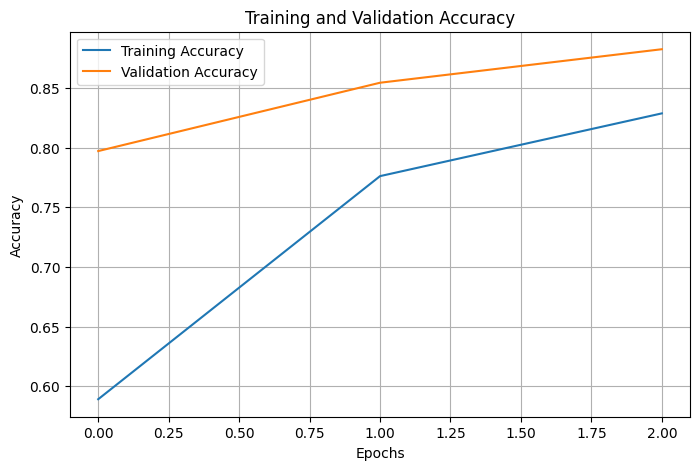

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

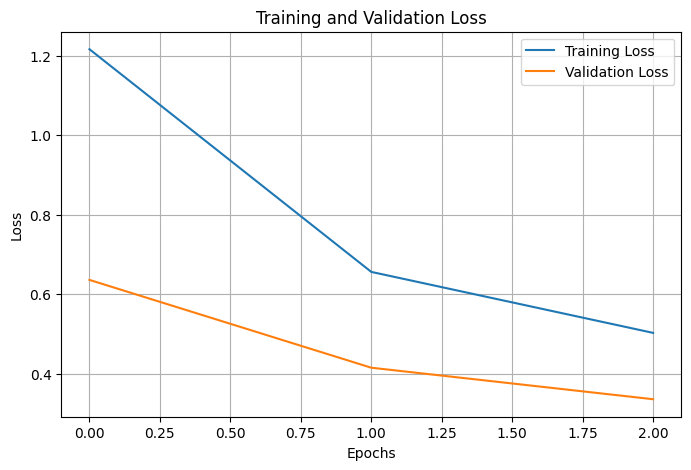

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

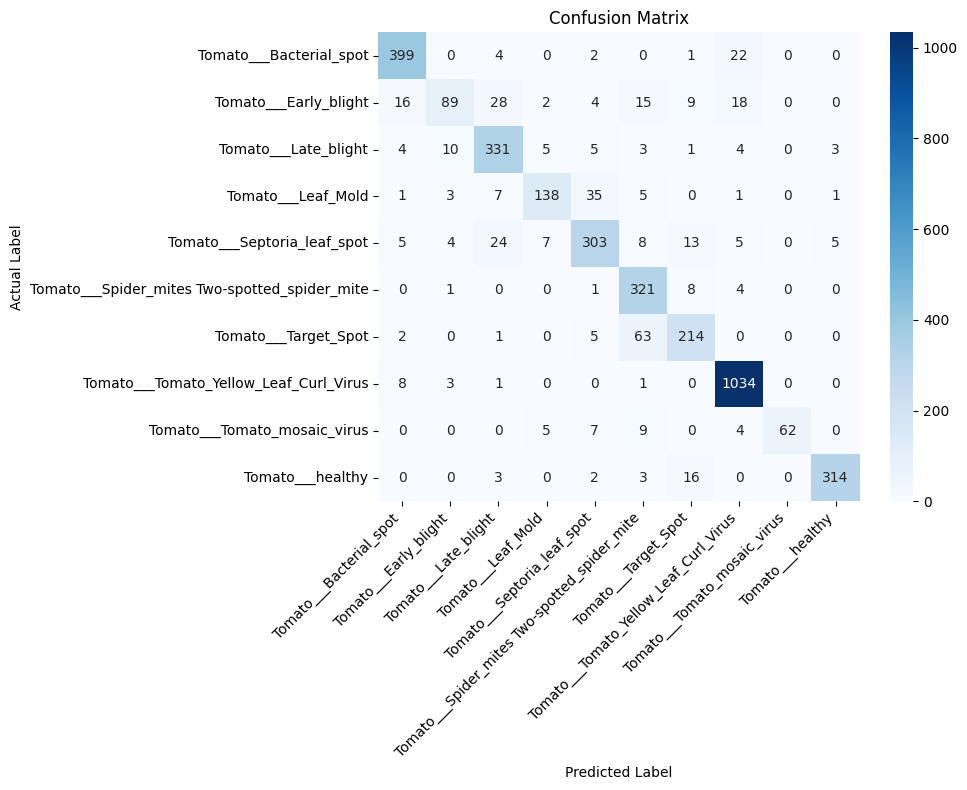

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot       0.92      0.93      0.92       428
                        Tomato___Early_blight       0.81      0.49      0.61       181
                         Tomato___Late_blight       0.83      0.90      0.87       366
                           Tomato___Leaf_Mold       0.88      0.72      0.79       191
                  Tomato___Septoria_leaf_spot       0.83      0.81      0.82       374
Tomato___Spider_mites Two-spotted_spider_mite       0.75      0.96      0.84       335
                         Tomato___Target_Spot       0.82      0.75      0.78       285
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.95      0.99      0.97      1047
                 Tomato___Tomato_mosaic_virus       1.00      0.71      0.83        87
                             Tomato___healthy       0.97      0.93      0.95       338

                                     accu

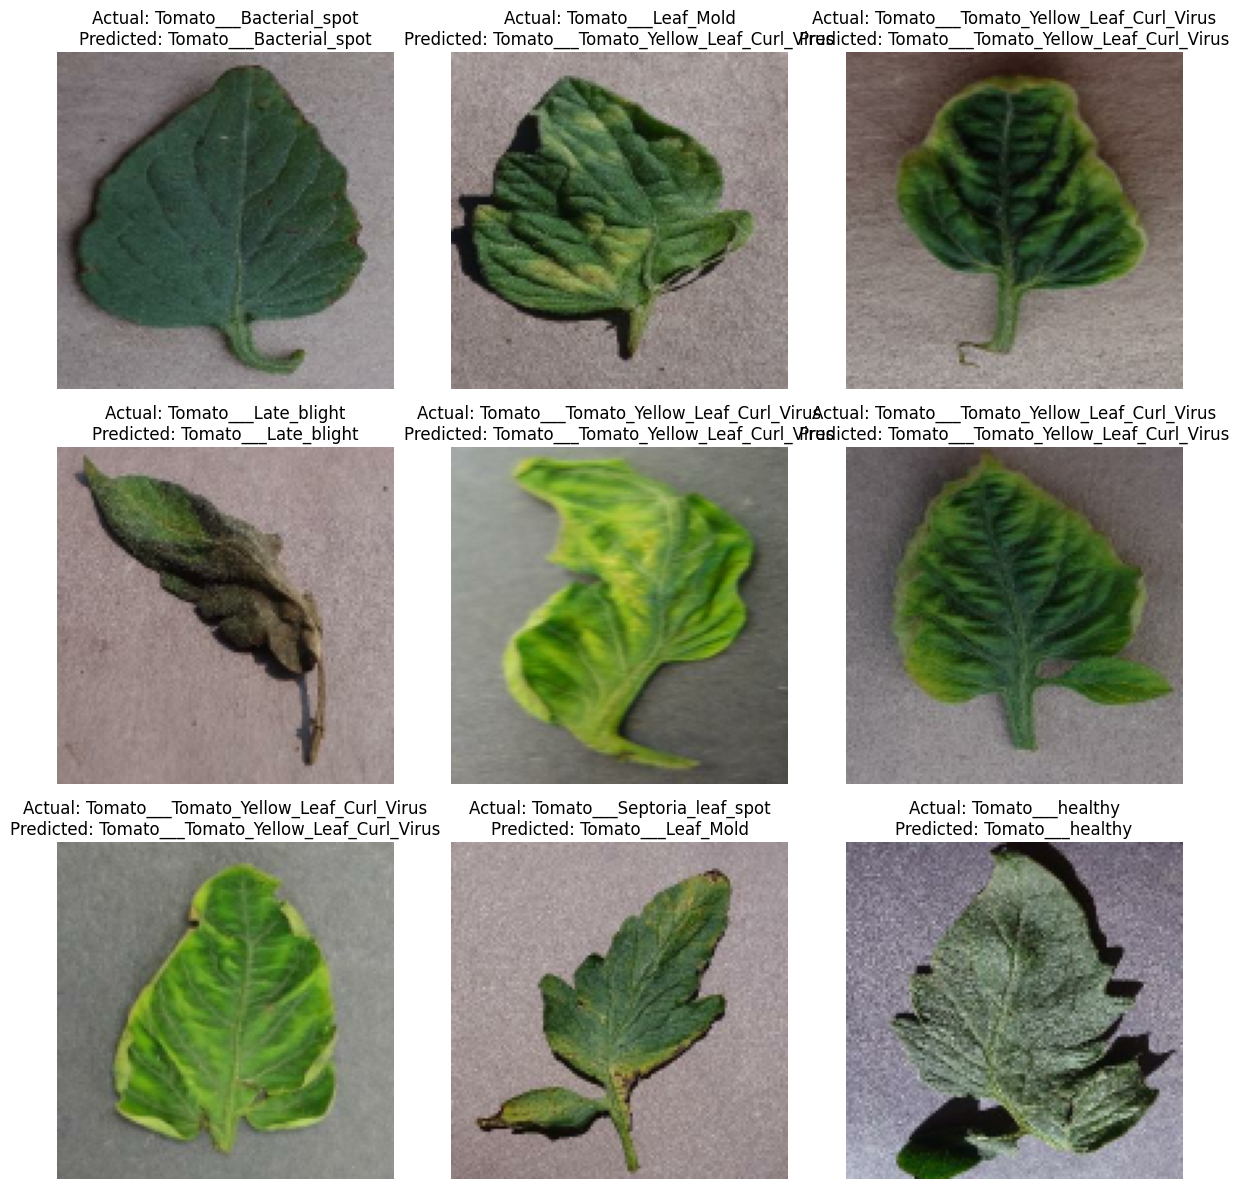

In [ ]:
plt.figure(figsize=(12, 12))

for images, labels in val_ds.take(1):
    predictions = model.predict(images, verbose=0)
    predicted_labels = np.argmax(predictions, axis=1)

    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy())

        actual = class_names[labels[i]]
        predicted = class_names[predicted_labels[i]]

        plt.title(
            "Actual: " + actual +
            "\nPredicted: " + predicted
        )

        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
correct_predictions = np.sum(
    np.array(y_true) == np.array(y_pred)
)

total_predictions = len(y_true)

manual_accuracy = correct_predictions / total_predictions

print("Correct Predictions:", correct_predictions)
print("Total Predictions:", total_predictions)
print("Manual Accuracy:", manual_accuracy)

Correct Predictions: 3205
Total Predictions: 3632
Manual Accuracy: 0.8824339207048458


In [ ]:
print("A Convolutional Neural Network was implemented for tomato disease classification.")
print("The CNN used convolution, pooling, flattening, dense and dropout layers.")
print("The model was trained for 3 epochs due to computational constraints.")
print("Model performance was evaluated using accuracy, loss curves, confusion matrix and classification report.")

A Convolutional Neural Network was implemented for tomato disease classification.
The CNN used convolution, pooling, flattening, dense and dropout layers.
The model was trained for 3 epochs due to computational constraints.
Model performance was evaluated using accuracy, loss curves, confusion matrix and classification report.
